<a href="https://colab.research.google.com/github/YashKasare21/DSA/blob/main/DeepECG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DeepECG: Cardiac Arrhythmia Detection using LSTM Autoencoder
Deep Learning mini-project | MIT-BIH Arrhythmia (Kaggle heartbeat version, 187 samples/beat, 5 AAMI classes)

**Modules**
1. Data loading + preprocessing + EDA
2. Baselines: MLP (2 hidden layers) and 1D-CNN
3. Gradient-descent variants study (SGD / Momentum / Nesterov / RMSprop / Adam)
4. Sequence autoencoders for anomaly detection: LSTM-AE (core), GRU-AE, RNN-AE
5. LSTM-AE encoder + classifier (5-class), evaluation and comparison

In [1]:
# Colab setup: install deps and fetch the MIT-BIH heartbeat dataset (needs a free Kaggle account)
# Option A (easiest): upload mitbih_train.csv and mitbih_test.csv to the Colab files panel (left sidebar).
# Option B: kagglehub download (it will ask you to log in once).
!pip -q install kagglehub
import os
if not (os.path.exists("mitbih_train.csv") and os.path.exists("mitbih_test.csv")):
    import kagglehub
    kagglehub.login()      # paste Kaggle username + API token when prompted


In [2]:
# Imports and configuration
import os, sys, json, time, random, warnings
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib

IN_NB = "ipykernel" in sys.modules
if not IN_NB:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve,
                             precision_recall_curve, precision_score, recall_score)

# DEEPECG_DEMO=1 -> tiny smoke test on one MIT-BIH record (only to verify the code runs)
DEMO = os.environ.get("DEEPECG_DEMO", "0") == "1"

CFG = dict(
    seed=42, T=187, batch=256,
    epochs_clf=30, epochs_opt=15, epochs_ae=25, patience=5,
    ae_units=(64, 32), max_ae_train=30000,
)
if DEMO:
    CFG.update(batch=64, epochs_clf=5, epochs_opt=3, epochs_ae=3, patience=3,
               ae_units=(32, 16), max_ae_train=None)

SEED = CFG["seed"]
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

OUT = Path(os.environ.get("DEEPECG_OUT", "outputs"))
FIG, MOD, RES = OUT / "figures", OUT / "models", OUT / "results"
for d in (FIG, MOD, RES):
    d.mkdir(parents=True, exist_ok=True)

CLASSES = ["N", "S", "V", "F", "Q"]
CLASS_FULL = ["Normal (N)", "Supraventricular (S)", "Ventricular (V)", "Fusion (F)", "Unknown (Q)"]
sns.set_theme(style="whitegrid", context="notebook")

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=200, bbox_inches="tight")
    if IN_NB:
        plt.show()
    plt.close(fig)

print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"), "| DEMO:", DEMO)

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | DEMO: False


## Module 1: Data loading and preprocessing
Kaggle "ECG Heartbeat Categorization Dataset": each row = one heartbeat (187 samples, already
min-max normalised to [0, 1]), last column = class (0 N, 1 S, 2 V, 3 F, 4 Q).

In [3]:
# Load data
def load_kaggle():
    cands = [Path("data"), Path("."), Path("/content"), Path("/content/data"),
             Path("/kaggle/input/heartbeat")]
    tr = te = None
    for d in cands:
        if (d / "mitbih_train.csv").exists() and (d / "mitbih_test.csv").exists():
            tr, te = d / "mitbih_train.csv", d / "mitbih_test.csv"
            break
    if tr is None:
        try:
            import kagglehub
            p = Path(kagglehub.dataset_download("shayanfazeli/heartbeat"))
            tr, te = p / "mitbih_train.csv", p / "mitbih_test.csv"
        except Exception as e:
            raise FileNotFoundError(
                "mitbih_train.csv / mitbih_test.csv not found. Download them from "
                "https://www.kaggle.com/datasets/shayanfazeli/heartbeat and put them in ./data/ "
                f"(auto-download failed: {e})")
    f = lambda p: pd.read_csv(p, header=None)
    a, b = f(tr), f(te)
    T = CFG["T"]
    return (a.iloc[:, :T].values.astype("float32"), a.iloc[:, T].values.astype(int),
            b.iloc[:, :T].values.astype("float32"), b.iloc[:, T].values.astype(int))


def load_demo():
    """Real MIT-BIH record 100 -> beats resampled to 187 samples. Smoke-test only."""
    import wfdb
    rec = wfdb.rdrecord("data/100"); ann = wfdb.rdann("data/100", "atr")
    sig, fs = rec.p_signal[:, 0], rec.fs
    sym2cls = {**{s: 0 for s in "NLRej"}, **{s: 1 for s in "AaJS"}, **{s: 2 for s in "VE"},
               "F": 3, **{s: 4 for s in "/fQ"}}
    half, T = int(0.75 * fs), CFG["T"]
    X, y = [], []
    for s, sym in zip(ann.sample, ann.symbol):
        if sym not in sym2cls or s - half < 0 or s + half > len(sig):
            continue
        seg = sig[s - half:s + half]
        seg = np.interp(np.linspace(0, len(seg) - 1, T), np.arange(len(seg)), seg)
        seg = (seg - seg.min()) / (seg.max() - seg.min() + 1e-8)
        X.append(seg); y.append(sym2cls[sym])
    X, y = np.array(X, "float32"), np.array(y)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
    return Xtr, ytr, Xte, yte


Xtr_all, ytr_all, Xte, yte = load_demo() if DEMO else load_kaggle()
if DEMO:
    Xtr, Xva, ytr, yva = train_test_split(Xtr_all, ytr_all, test_size=0.15, random_state=SEED)
else:
    Xtr, Xva, ytr, yva = train_test_split(Xtr_all, ytr_all, test_size=0.1,
                                          stratify=ytr_all, random_state=SEED)
print(f"train {Xtr.shape} | val {Xva.shape} | test {Xte.shape}")
dist = pd.DataFrame({"class": CLASS_FULL,
                     "train": np.bincount(ytr, minlength=5),
                     "val": np.bincount(yva, minlength=5),
                     "test": np.bincount(yte, minlength=5)})
print(dist.to_string(index=False))
dist.to_csv(RES / "class_distribution.csv", index=False)

100%|██████████| 98.8M/98.8M [00:00<00:00, 129MB/s]

Extracting files...


train (78798, 187) | val (8756, 187) | test (21892, 187)
               class  train  val  test
          Normal (N)  65223 7248 18118
Supraventricular (S)   2001  222   556
     Ventricular (V)   5209  579  1448
          Fusion (F)    577   64   162
         Unknown (Q)   5788  643  1608


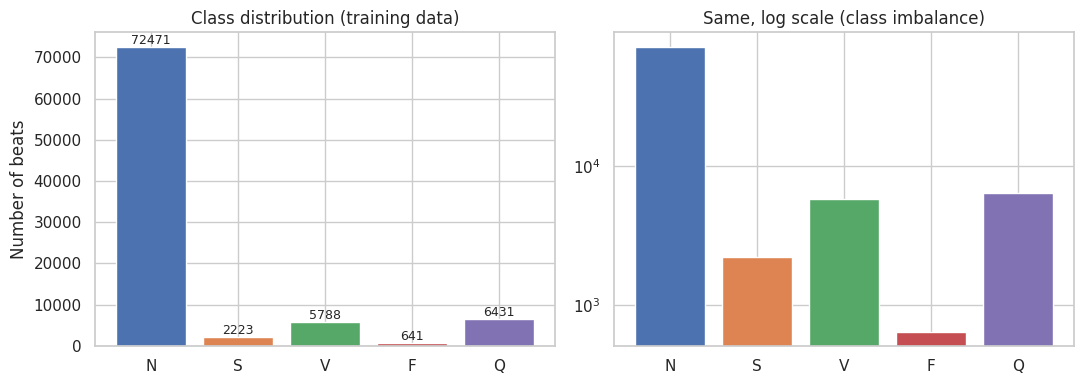

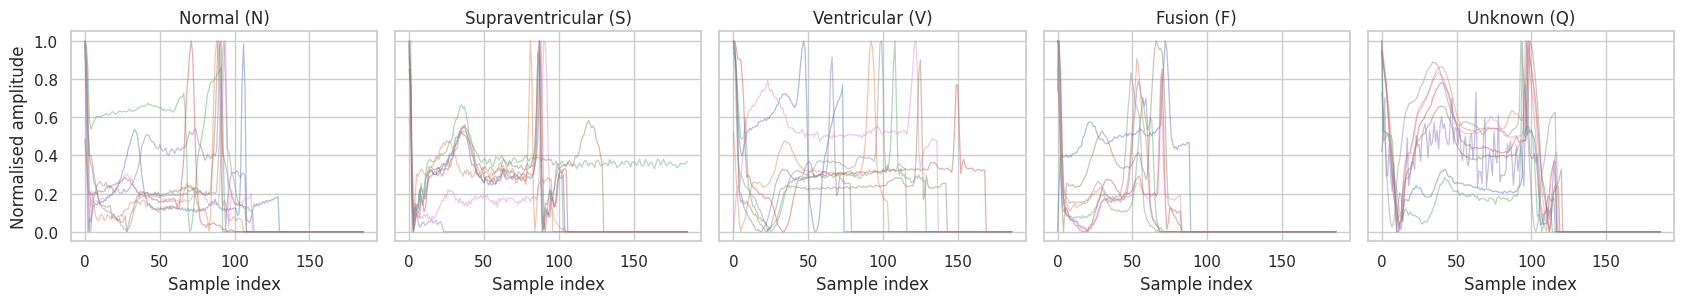

In [4]:
# EDA figures
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tot = np.bincount(np.concatenate([ytr, yva]), minlength=5)
ax[0].bar(CLASSES, tot, color=sns.color_palette("deep", 5))
ax[0].set_title("Class distribution (training data)"); ax[0].set_ylabel("Number of beats")
for i, v in enumerate(tot):
    ax[0].text(i, v, str(v), ha="center", va="bottom", fontsize=9)
ax[1].bar(CLASSES, tot, color=sns.color_palette("deep", 5)); ax[1].set_yscale("log")
ax[1].set_title("Same, log scale (class imbalance)")
save_fig(fig, "fig01_class_distribution.png")

fig, axes = plt.subplots(1, 5, figsize=(17, 3.2), sharey=True)
for c, a in enumerate(axes):
    idx = np.where(ytr == c)[0][:8]
    for i in idx:
        a.plot(Xtr[i], alpha=0.45, lw=0.9)
    a.set_title(CLASS_FULL[c]); a.set_xlabel("Sample index")
axes[0].set_ylabel("Normalised amplitude")
save_fig(fig, "fig02_sample_beats_per_class.png")

In [5]:
# Helpers: training, evaluation, plotting
def fit_model(model, Xt, yt, Xv, yv, epochs, class_weight=None, verbose=2):
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG["patience"],
                                        restore_best_weights=True)]
    t0 = time.time()
    h = model.fit(Xt, yt, validation_data=(Xv, yv), epochs=epochs, batch_size=CFG["batch"],
                  class_weight=class_weight, callbacks=cb, verbose=verbose)
    return h.history, time.time() - t0


def eval_clf(name, model, X, y):
    p = model.predict(X, batch_size=1024, verbose=0)
    yp = p.argmax(1)
    present = sorted(set(y) | set(yp))
    rep = classification_report(y, yp, labels=present, target_names=[CLASS_FULL[i] for i in present],
                                zero_division=0, digits=4)
    return dict(name=name, yp=yp, acc=accuracy_score(y, yp),
                macro_f1=f1_score(y, yp, average="macro", labels=present, zero_division=0),
                weighted_f1=f1_score(y, yp, average="weighted", zero_division=0), report=rep)


def summary_text(model):
    lines = []
    model.summary(print_fn=lambda s, **k: lines.append(s))
    return "\n".join(lines)


cls_w = compute_class_weight("balanced", classes=np.unique(ytr), y=ytr)
CW = {int(c): float(w) for c, w in zip(np.unique(ytr), cls_w)}
# cap extreme weights so very rare classes do not destabilise training
CW = {k: min(v, 20.0) for k, v in CW.items()}
print("class weights:", {CLASSES[k]: round(v, 2) for k, v in CW.items()})
Xtr3, Xva3, Xte3 = Xtr[..., None], Xva[..., None], Xte[..., None]
summaries, reports, results = {}, {}, []

class weights: {'N': 0.24, 'S': 7.88, 'V': 3.03, 'F': 20.0, 'Q': 2.72}


## Module 2: Baselines (MLP with 2 hidden layers, 1D-CNN)

In [6]:
# Baseline models
def build_mlp(opt="adam"):
    m = keras.Sequential([
        layers.Input((CFG["T"],)),
        layers.Dense(128, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(5, activation="softmax")], name="MLP_2hidden")
    m.compile(opt, "sparse_categorical_crossentropy", metrics=["accuracy"])
    return m


def build_cnn():
    m = keras.Sequential([
        layers.Input((CFG["T"], 1)),
        layers.Conv1D(32, 5, padding="same"), layers.BatchNormalization(), layers.ReLU(), layers.MaxPooling1D(2),
        layers.Conv1D(64, 5, padding="same"), layers.BatchNormalization(), layers.ReLU(), layers.MaxPooling1D(2),
        layers.Conv1D(128, 3, padding="same"), layers.BatchNormalization(), layers.ReLU(),
        layers.GlobalAveragePooling1D(),
        layers.Dense(64, activation="relu"), layers.Dropout(0.3),
        layers.Dense(5, activation="softmax")], name="CNN_1D")
    m.compile(keras.optimizers.Adam(1e-3), "sparse_categorical_crossentropy", metrics=["accuracy"])
    return m


mlp, cnn = build_mlp(), build_cnn()
summaries["MLP"], summaries["1D-CNN"] = summary_text(mlp), summary_text(cnn)
print(summaries["MLP"]); print(summaries["1D-CNN"])

hist_mlp, t_mlp = fit_model(mlp, Xtr, ytr, Xva, yva, CFG["epochs_clf"], CW)
hist_cnn, t_cnn = fit_model(cnn, Xtr3, ytr, Xva3, yva, CFG["epochs_clf"], CW)
r_mlp = eval_clf("MLP (2 hidden layers)", mlp, Xte, yte)
r_cnn = eval_clf("1D-CNN", cnn, Xte3, yte)
for r, t, m in ((r_mlp, t_mlp, mlp), (r_cnn, t_cnn, cnn)):
    reports[r["name"]] = r["report"]
    results.append(dict(Model=r["name"], Task="5-class classification", Accuracy=r["acc"],
                        Macro_F1=r["macro_f1"], Weighted_F1=r["weighted_f1"],
                        Params=m.count_params(), Train_time_s=round(t, 1)))
    print(f"\n{r['name']}: acc={r['acc']:.4f} macroF1={r['macro_f1']:.4f}\n{r['report']}")
mlp.save(MOD / "mlp.keras"); cnn.save(MOD / "cnn1d.keras")

Model: "MLP_2hidden"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        24,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 32,645 (127.52 KB)
 Trainable params: 32,645 (127.52 KB)
 Non-trainable params: 0 (0.00 B)

Model: "CNN_1D"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━

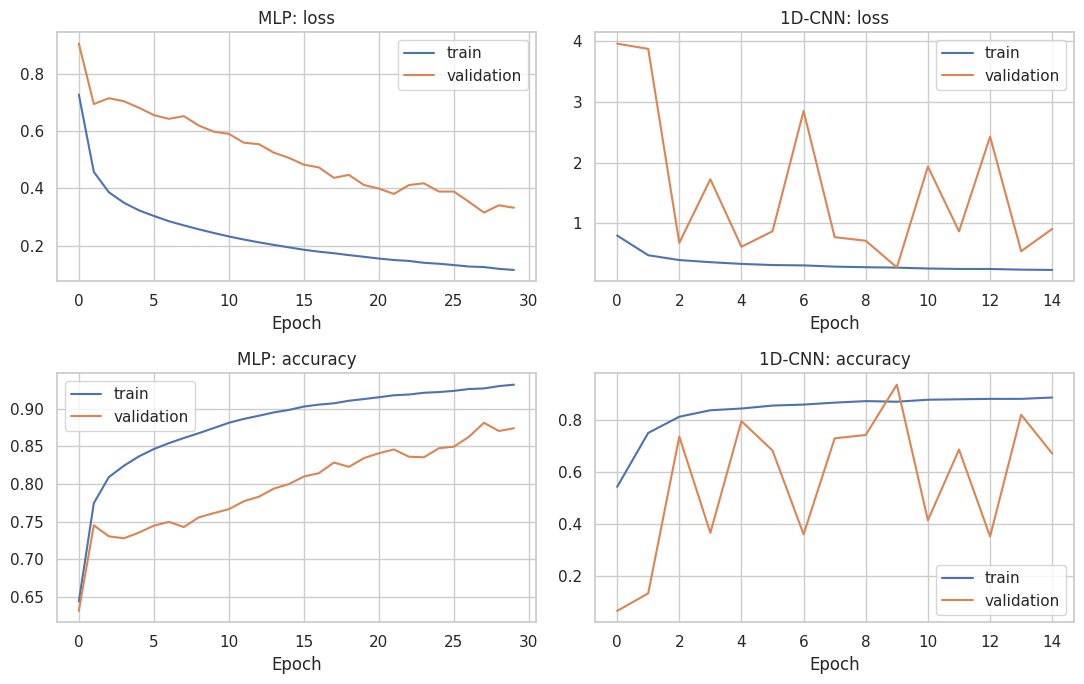

In [7]:
# Training curves for baselines
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for j, (nm, h) in enumerate((("MLP", hist_mlp), ("1D-CNN", hist_cnn))):
    ax[0, j].plot(h["loss"], label="train"); ax[0, j].plot(h["val_loss"], label="validation")
    ax[0, j].set_title(f"{nm}: loss"); ax[0, j].set_xlabel("Epoch"); ax[0, j].legend()
    ax[1, j].plot(h["accuracy"], label="train"); ax[1, j].plot(h["val_accuracy"], label="validation")
    ax[1, j].set_title(f"{nm}: accuracy"); ax[1, j].set_xlabel("Epoch"); ax[1, j].legend()
save_fig(fig, "fig03_baseline_training_curves.png")

## Module 3: Gradient-descent variants (same MLP, different optimisers)

SGD (lr=0.01)              val_acc=0.6560  test_acc=0.6503
SGD + Momentum (0.9)       val_acc=0.8274  test_acc=0.8234
SGD + Nesterov (0.9)       val_acc=0.8730  test_acc=0.8710
RMSprop (1e-3)             val_acc=0.9009  test_acc=0.8967
Adam (1e-3)                val_acc=0.7998  test_acc=0.7915


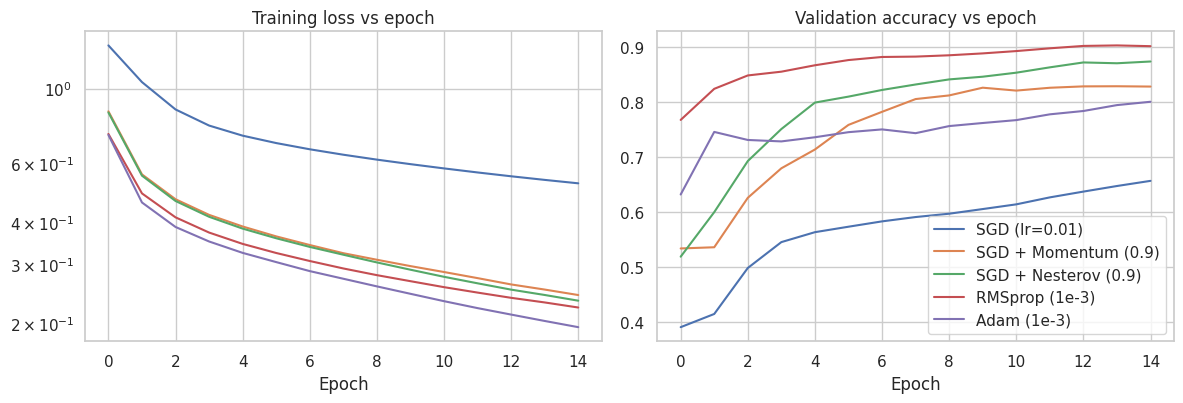

In [8]:
# Optimiser study
OPTS = {
    "SGD (lr=0.01)": lambda: keras.optimizers.SGD(0.01),
    "SGD + Momentum (0.9)": lambda: keras.optimizers.SGD(0.01, momentum=0.9),
    "SGD + Nesterov (0.9)": lambda: keras.optimizers.SGD(0.01, momentum=0.9, nesterov=True),
    "RMSprop (1e-3)": lambda: keras.optimizers.RMSprop(1e-3),
    "Adam (1e-3)": lambda: keras.optimizers.Adam(1e-3),
}
opt_hist, opt_rows = {}, []
for name, mk in OPTS.items():
    keras.utils.set_random_seed(SEED)
    m = build_mlp(mk())
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=CFG["epochs_opt"],
              batch_size=CFG["batch"], class_weight=CW, verbose=0)
    opt_hist[name] = h.history
    p = m.predict(Xte, verbose=0).argmax(1)
    opt_rows.append(dict(Optimizer=name, Final_train_loss=h.history["loss"][-1],
                         Final_val_loss=h.history["val_loss"][-1],
                         Final_val_acc=h.history["val_accuracy"][-1],
                         Test_acc=accuracy_score(yte, p),
                         Test_macro_F1=f1_score(yte, p, average="macro", zero_division=0)))
    print(f"{name:26s} val_acc={h.history['val_accuracy'][-1]:.4f}  test_acc={opt_rows[-1]['Test_acc']:.4f}")
opt_df = pd.DataFrame(opt_rows); opt_df.to_csv(RES / "optimizer_comparison.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for name, h in opt_hist.items():
    ax[0].plot(h["loss"], label=name); ax[1].plot(h["val_accuracy"], label=name)
ax[0].set_title("Training loss vs epoch"); ax[0].set_xlabel("Epoch"); ax[0].set_yscale("log")
ax[1].set_title("Validation accuracy vs epoch"); ax[1].set_xlabel("Epoch"); ax[1].legend()
save_fig(fig, "fig04_optimizer_comparison.png")

## Module 4: Sequence autoencoders (LSTM-AE core, GRU-AE, RNN-AE)
Trained **only on normal beats**. Reconstruction error (MSE) is the anomaly score.

In [9]:
# Build / train autoencoders
PATCH = 4                                   # 4 consecutive samples = 1 RNN time-step
N_STEPS = int(np.ceil(CFG["T"] / PATCH))    # 187 -> padded to 188 -> 47 time-steps


def build_ae(cell, tag, units=CFG["ae_units"], T=CFG["T"]):
    """Sequence autoencoder. The 187-sample beat is reshaped to 47 steps x 4 features (lossless),
    which makes long-range learning far easier than a raw 187-step RNN and trains ~4x faster."""
    u1, u2 = units
    pad = N_STEPS * PATCH - T
    inp = layers.Input((T, 1))
    x = layers.ZeroPadding1D((0, pad))(inp)
    x = layers.Reshape((N_STEPS, PATCH))(x)
    x = cell(u1, return_sequences=True)(x)
    z = cell(u2, name=f"{tag}_latent")(x)                  # bottleneck (latent code)
    x = layers.RepeatVector(N_STEPS)(z)
    x = cell(u2, return_sequences=True)(x)
    x = cell(u1, return_sequences=True)(x)
    x = layers.Dense(PATCH)(x)
    x = layers.Reshape((N_STEPS * PATCH, 1))(x)
    out = layers.Cropping1D((0, pad))(x)
    ae = keras.Model(inp, out, name=f"{tag}_Autoencoder")
    enc = keras.Model(inp, z, name=f"{tag}_Encoder")
    ae.compile(keras.optimizers.Adam(1e-3, clipnorm=1.0), "mse")
    return ae, enc


def recon_error(ae, X3):
    rec = ae.predict(X3, batch_size=512, verbose=0)
    return np.mean((X3 - rec) ** 2, axis=(1, 2)), rec


Xn_tr = Xtr3[ytr == 0]
if CFG["max_ae_train"] and len(Xn_tr) > CFG["max_ae_train"]:
    Xn_tr = Xn_tr[np.random.RandomState(SEED).choice(len(Xn_tr), CFG["max_ae_train"], replace=False)]
Xn_va = Xva3[yva == 0]
print("AE training beats (normal only):", Xn_tr.shape, "| AE validation:", Xn_va.shape)

AE = {}
for tag, cell in (("LSTM", layers.LSTM), ("GRU", layers.GRU), ("RNN", layers.SimpleRNN)):
    keras.utils.set_random_seed(SEED)
    ae, enc = build_ae(cell, tag)
    summaries[f"{tag}-AE"] = summary_text(ae)
    print(f"\n=== {tag}-Autoencoder ({ae.count_params():,} params) ===")
    h, t = fit_model(ae, Xn_tr, Xn_tr, Xn_va, Xn_va, CFG["epochs_ae"])
    AE[tag] = dict(ae=ae, enc=enc, hist=h, time=t)
    ae.save(MOD / f"{tag.lower()}_autoencoder.keras")

AE training beats (normal only): (30000, 187, 1) | AE validation: (7248, 187, 1)



=== LSTM-Autoencoder (63,492 params) ===
Epoch 1/25
118/118 - 8s - 65ms/step - loss: 0.0313 - val_loss: 0.0237
Epoch 2/25
118/118 - 2s - 16ms/step - loss: 0.0216 - val_loss: 0.0189
Epoch 3/25
118/118 - 2s - 16ms/step - loss: 0.0180 - val_loss: 0.0171
Epoch 4/25
118/118 - 2s - 16ms/step - loss: 0.0165 - val_loss: 0.0157
Epoch 5/25
118/118 - 2s - 15ms/step - loss: 0.0150 - val_loss: 0.0134
Epoch 6/25
118/118 - 2s - 16ms/step - loss: 0.0116 - val_loss: 0.0104
Epoch 7/25
118/118 - 2s - 16ms/step - loss: 0.0104 - val_loss: 0.0104
Epoch 8/25
118/118 - 2s - 15ms/step - loss: 0.0099 - val_loss: 0.0109
Epoch 9/25
118/118 - 2s - 16ms/step - loss: 0.0096 - val_loss: 0.0092
Epoch 10/25
118/118 - 2s - 16ms/step - loss: 0.0093 - val_loss: 0.0089
Epoch 11/25
118/118 - 2s - 16ms/step - loss: 0.0087 - val_loss: 0.0084
Epoch 12/25
118/118 - 2s - 16ms/step - loss: 0.0084 - val_loss: 0.0083
Epoch 13/25
118/118 - 2s - 16ms/step - loss: 0.0080 - val_loss: 0.0078
Epoch 14/25
118/118 - 2s - 16ms/step - loss:


=== GRU-Autoencoder (48,260 params) ===
Epoch 1/25
118/118 - 5s - 42ms/step - loss: 0.0371 - val_loss: 0.0241
Epoch 2/25
118/118 - 2s - 16ms/step - loss: 0.0197 - val_loss: 0.0171
Epoch 3/25
118/118 - 2s - 15ms/step - loss: 0.0157 - val_loss: 0.0140
Epoch 4/25
118/118 - 2s - 15ms/step - loss: 0.0137 - val_loss: 0.0126
Epoch 5/25
118/118 - 2s - 15ms/step - loss: 0.0125 - val_loss: 0.0128
Epoch 6/25
118/118 - 2s - 15ms/step - loss: 0.0120 - val_loss: 0.0115
Epoch 7/25
118/118 - 2s - 16ms/step - loss: 0.0116 - val_loss: 0.0113
Epoch 8/25
118/118 - 2s - 16ms/step - loss: 0.0111 - val_loss: 0.0110
Epoch 9/25
118/118 - 2s - 15ms/step - loss: 0.0108 - val_loss: 0.0103
Epoch 10/25
118/118 - 2s - 15ms/step - loss: 0.0104 - val_loss: 0.0110
Epoch 11/25
118/118 - 2s - 15ms/step - loss: 0.0101 - val_loss: 0.0101
Epoch 12/25
118/118 - 3s - 22ms/step - loss: 0.0096 - val_loss: 0.0096
Epoch 13/25
118/118 - 2s - 15ms/step - loss: 0.0092 - val_loss: 0.0094
Epoch 14/25
118/118 - 2s - 15ms/step - loss: 


=== RNN-Autoencoder (16,068 params) ===
Epoch 1/25
118/118 - 16s - 132ms/step - loss: 0.0442 - val_loss: 0.0256
Epoch 2/25
118/118 - 2s - 19ms/step - loss: 0.0258 - val_loss: 0.0204
Epoch 3/25
118/118 - 2s - 18ms/step - loss: 0.0206 - val_loss: 0.0192
Epoch 4/25
118/118 - 2s - 18ms/step - loss: 0.0187 - val_loss: 0.0179
Epoch 5/25
118/118 - 2s - 18ms/step - loss: 0.0168 - val_loss: 0.0160
Epoch 6/25
118/118 - 2s - 18ms/step - loss: 0.0155 - val_loss: 0.0145
Epoch 7/25
118/118 - 2s - 18ms/step - loss: 0.0136 - val_loss: 0.0132
Epoch 8/25
118/118 - 2s - 18ms/step - loss: 0.0135 - val_loss: 0.0132
Epoch 9/25
118/118 - 2s - 18ms/step - loss: 0.0123 - val_loss: 0.0139
Epoch 10/25
118/118 - 2s - 18ms/step - loss: 0.0122 - val_loss: 0.0129
Epoch 11/25
118/118 - 2s - 18ms/step - loss: 0.0118 - val_loss: 0.0113
Epoch 12/25
118/118 - 2s - 18ms/step - loss: 0.0117 - val_loss: 0.0114
Epoch 13/25
118/118 - 2s - 18ms/step - loss: 0.0113 - val_loss: 0.0112
Epoch 14/25
118/118 - 2s - 18ms/step - loss

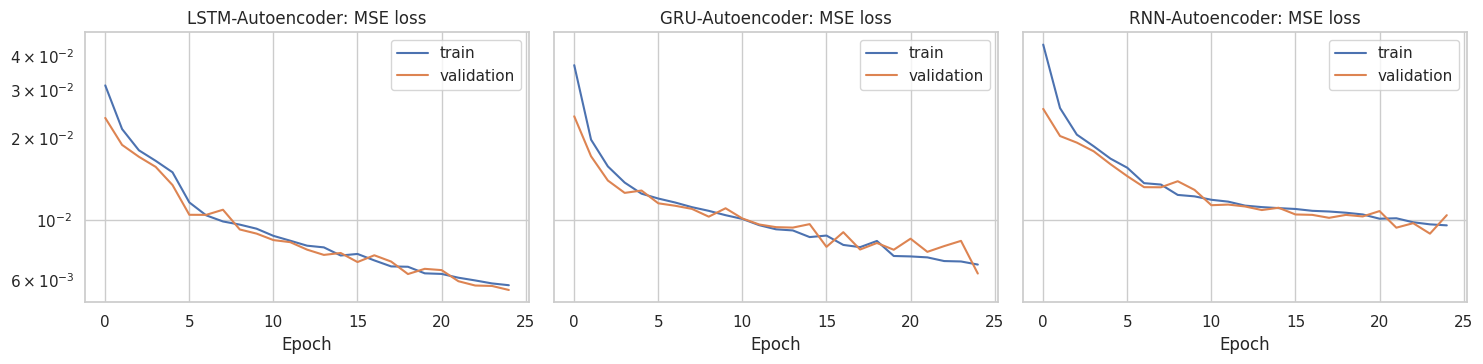

In [10]:
# AE training curves
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, (tag, d) in zip(ax, AE.items()):
    a.plot(d["hist"]["loss"], label="train"); a.plot(d["hist"]["val_loss"], label="validation")
    a.set_title(f"{tag}-Autoencoder: MSE loss"); a.set_xlabel("Epoch"); a.set_yscale("log"); a.legend()
save_fig(fig, "fig05_autoencoder_training_curves.png")

In [11]:
# Anomaly detection evaluation
def best_f1_threshold(err, lab):
    if lab.sum() == 0:
        return float(np.percentile(err[lab == 0], 95))
    p, r, t = precision_recall_curve(lab, err)
    f1 = 2 * p * r / (p + r + 1e-12)
    return float(t[np.argmax(f1[:-1])])


lab_va, lab_te = (yva != 0).astype(int), (yte != 0).astype(int)
anom_rows = []
for tag, d in AE.items():
    e_va, _ = recon_error(d["ae"], Xva3)
    e_te, rec_te = recon_error(d["ae"], Xte3)
    thr = best_f1_threshold(e_va, lab_va)                 # threshold chosen on validation set only
    pred = (e_te > thr).astype(int)
    d.update(e_te=e_te, rec_te=rec_te, thr=thr)
    auc = roc_auc_score(lab_te, e_te) if lab_te.sum() else float("nan")
    row = dict(Model=f"{tag}-Autoencoder", ROC_AUC=auc,
               Precision=precision_score(lab_te, pred, zero_division=0),
               Recall=recall_score(lab_te, pred, zero_division=0),
               F1=f1_score(lab_te, pred, zero_division=0),
               Accuracy=accuracy_score(lab_te, pred), Threshold=thr,
               Params=d["ae"].count_params(), Train_time_s=round(d["time"], 1))
    anom_rows.append(row)
    d["pred"] = pred
    print(f"{tag}-AE  AUC={auc:.4f}  P={row['Precision']:.4f}  R={row['Recall']:.4f}  F1={row['F1']:.4f}  thr={thr:.5f}")
anom_df = pd.DataFrame(anom_rows); anom_df.to_csv(RES / "anomaly_detection_results.csv", index=False)

LSTM-AE  AUC=0.8536  P=0.5827  R=0.6489  F1=0.6140  thr=0.01039
GRU-AE  AUC=0.8386  P=0.5659  R=0.6290  F1=0.5958  thr=0.01131
RNN-AE  AUC=0.7694  P=0.4343  R=0.5599  F1=0.4892  thr=0.01227


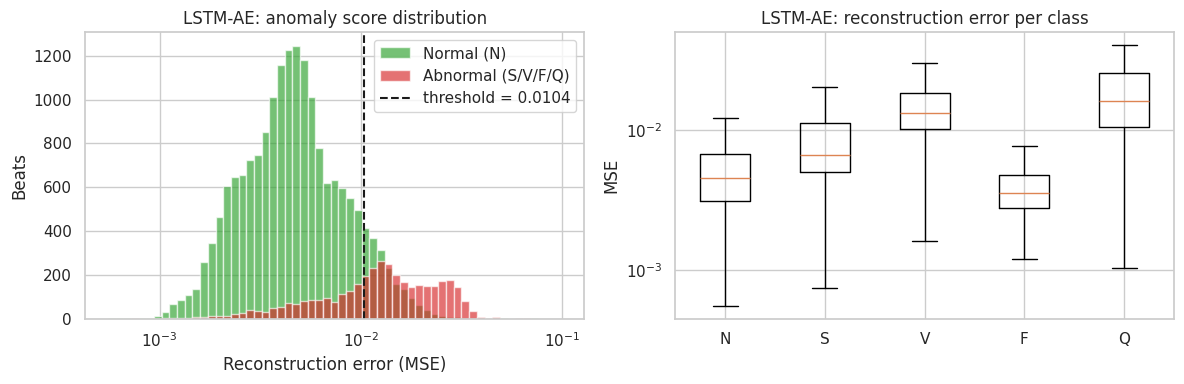

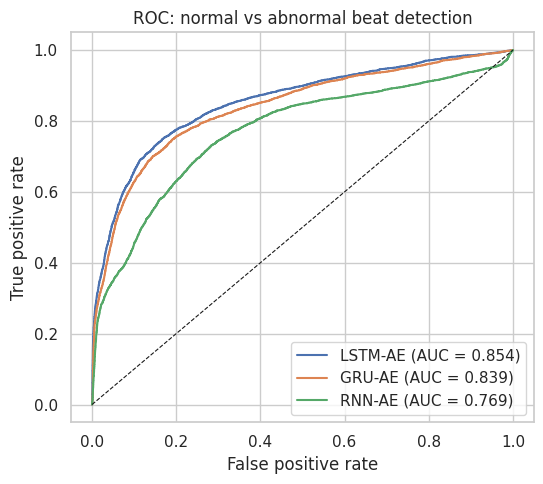

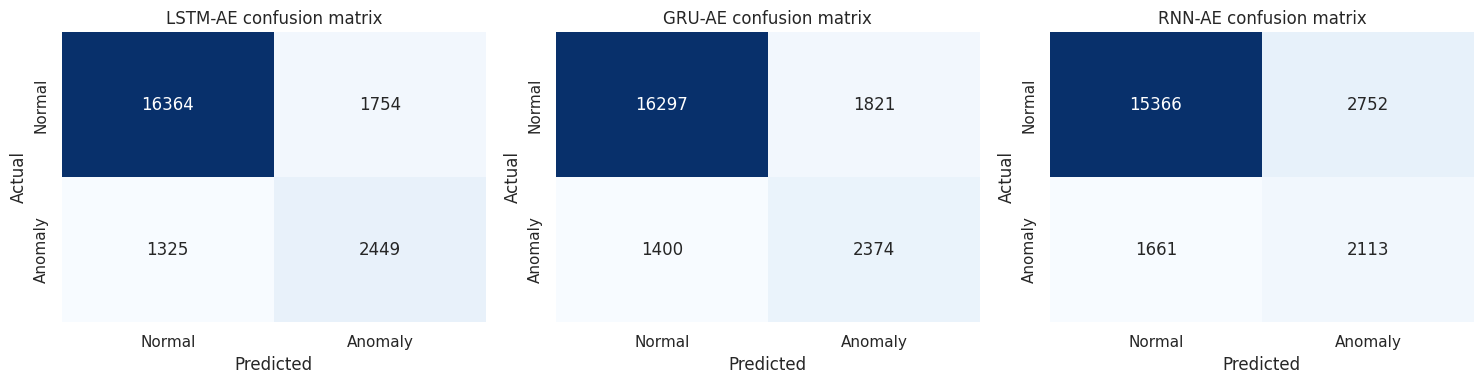

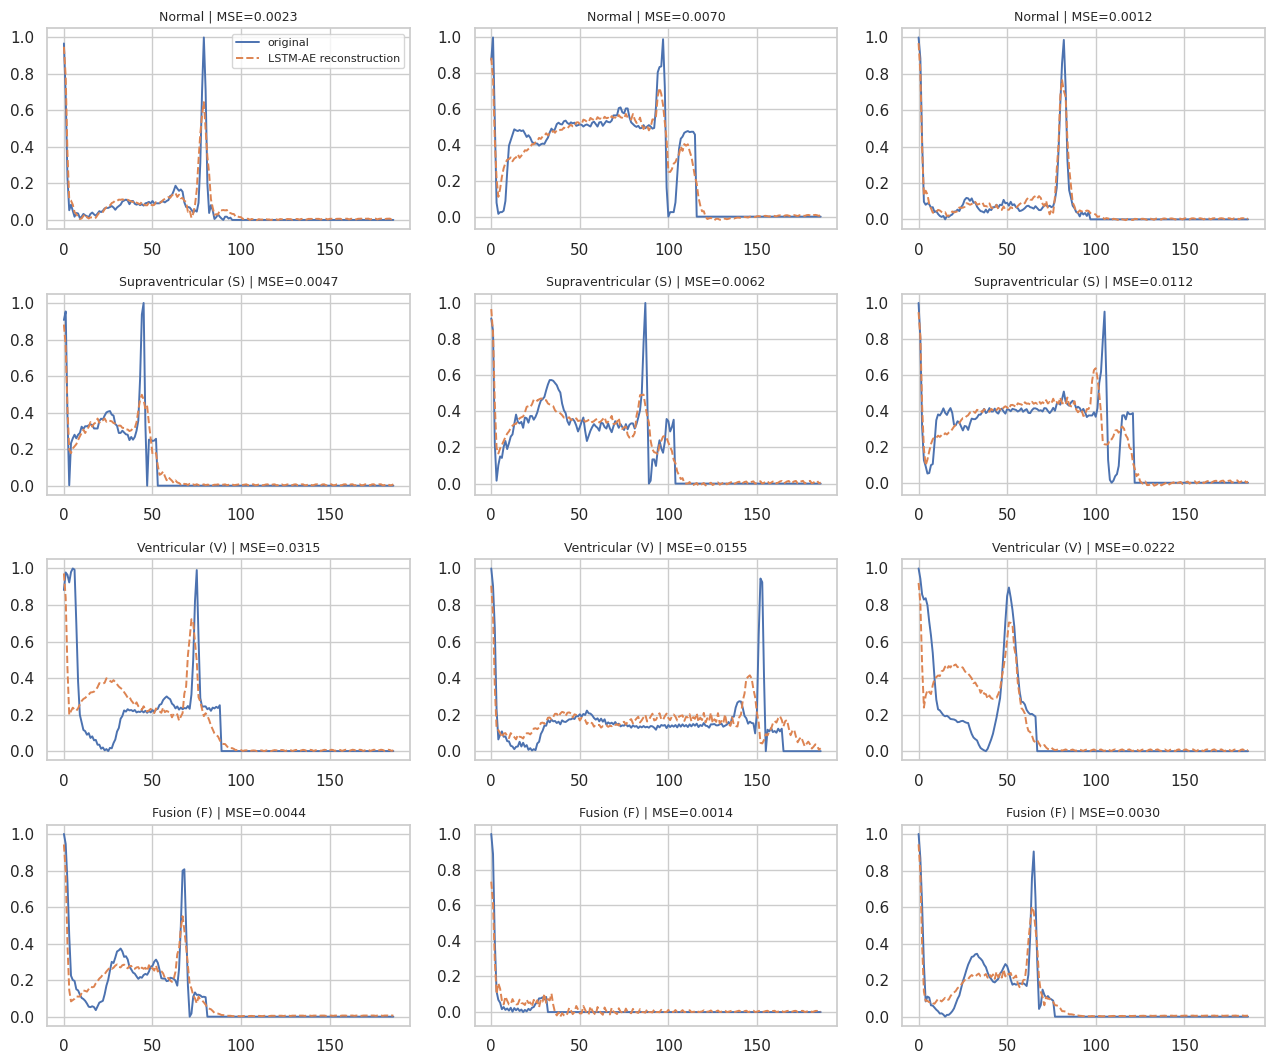

In [12]:
# Anomaly figures: score distribution, ROC, confusion, reconstructions
L = AE["LSTM"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bins = np.logspace(np.log10(max(L["e_te"].min(), 1e-6)), np.log10(L["e_te"].max()), 60)
ax[0].hist(L["e_te"][lab_te == 0], bins=bins, alpha=0.65, label="Normal (N)", color="tab:green")
ax[0].hist(L["e_te"][lab_te == 1], bins=bins, alpha=0.65, label="Abnormal (S/V/F/Q)", color="tab:red")
ax[0].axvline(L["thr"], color="k", ls="--", label=f"threshold = {L['thr']:.4f}")
ax[0].set_xscale("log"); ax[0].set_xlabel("Reconstruction error (MSE)"); ax[0].set_ylabel("Beats")
ax[0].set_title("LSTM-AE: anomaly score distribution"); ax[0].legend()
data = [L["e_te"][yte == c] for c in range(5) if (yte == c).any()]
labs = [CLASSES[c] for c in range(5) if (yte == c).any()]
ax[1].boxplot(data, labels=labs, showfliers=False); ax[1].set_yscale("log")
ax[1].set_title("LSTM-AE: reconstruction error per class"); ax[1].set_ylabel("MSE")
save_fig(fig, "fig06_anomaly_score_distribution.png")

if lab_te.sum():
    fig, ax = plt.subplots(figsize=(5.6, 5))
    for tag, d in AE.items():
        fpr, tpr, _ = roc_curve(lab_te, d["e_te"])
        ax.plot(fpr, tpr, label=f"{tag}-AE (AUC = {roc_auc_score(lab_te, d['e_te']):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title("ROC: normal vs abnormal beat detection"); ax.legend(loc="lower right")
    save_fig(fig, "fig07_roc_autoencoders.png")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (tag, d) in zip(ax, AE.items()):
    cm = confusion_matrix(lab_te, d["pred"], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
    a.set_title(f"{tag}-AE confusion matrix"); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
save_fig(fig, "fig08_anomaly_confusion_matrices.png")

rs = np.random.RandomState(SEED)
picks = [("Normal", rs.choice(np.where(yte == 0)[0], 3, replace=False))]
for c in (1, 2, 3):
    if (yte == c).sum():
        picks.append((CLASS_FULL[c], rs.choice(np.where(yte == c)[0], min(3, (yte == c).sum()), replace=False)))
nrow = len(picks)
fig, ax = plt.subplots(nrow, 3, figsize=(13, 2.7 * nrow), squeeze=False)
for i, (nm, ids) in enumerate(picks):
    for j in range(3):
        a = ax[i, j]
        if j < len(ids):
            k = ids[j]
            a.plot(Xte[k], label="original", lw=1.4)
            a.plot(L["rec_te"][k, :, 0], "--", label="LSTM-AE reconstruction", lw=1.4)
            a.set_title(f"{nm} | MSE={L['e_te'][k]:.4f}", fontsize=9)
            if i == 0 and j == 0:
                a.legend(fontsize=8)
        else:
            a.axis("off")
save_fig(fig, "fig09_reconstruction_examples.png")

## Module 5: LSTM-AE encoder as feature extractor + 5-class classifier

In [13]:
# Encoder + classifier
enc = AE["LSTM"]["enc"]
Ztr, Zva, Zte = (enc.predict(a, batch_size=512, verbose=0) for a in (Xtr3, Xva3, Xte3))
head = keras.Sequential([layers.Input((Ztr.shape[1],)), layers.Dense(64, activation="relu"),
                         layers.Dropout(0.2), layers.Dense(5, activation="softmax")],
                        name="LSTM_AE_classifier_head")
head.compile(keras.optimizers.Adam(1e-3), "sparse_categorical_crossentropy", metrics=["accuracy"])
hist_head, t_head = fit_model(head, Ztr, ytr, Zva, yva, CFG["epochs_clf"], CW, verbose=0)
r_head = eval_clf("LSTM-AE encoder + classifier", head, Zte, yte)
reports[r_head["name"]] = r_head["report"]
results.append(dict(Model=r_head["name"], Task="5-class classification", Accuracy=r_head["acc"],
                    Macro_F1=r_head["macro_f1"], Weighted_F1=r_head["weighted_f1"],
                    Params=AE["LSTM"]["enc"].count_params() + head.count_params(),
                    Train_time_s=round(AE["LSTM"]["time"] + t_head, 1)))
print(f"{r_head['name']}: acc={r_head['acc']:.4f} macroF1={r_head['macro_f1']:.4f}\n{r_head['report']}")

LSTM-AE encoder + classifier: acc=0.5687 macroF1=0.4120
                      precision    recall  f1-score   support

          Normal (N)     0.9750    0.5249    0.6824     18118
Supraventricular (S)     0.1020    0.7392    0.1793       556
     Ventricular (V)     0.3145    0.7093    0.4358      1448
          Fusion (F)     0.0632    0.8704    0.1179       162
         Unknown (Q)     0.5207    0.8464    0.6447      1608

            accuracy                         0.5687     21892
           macro avg     0.3951    0.7380    0.4120     21892
        weighted avg     0.8690    0.5687    0.6464     21892



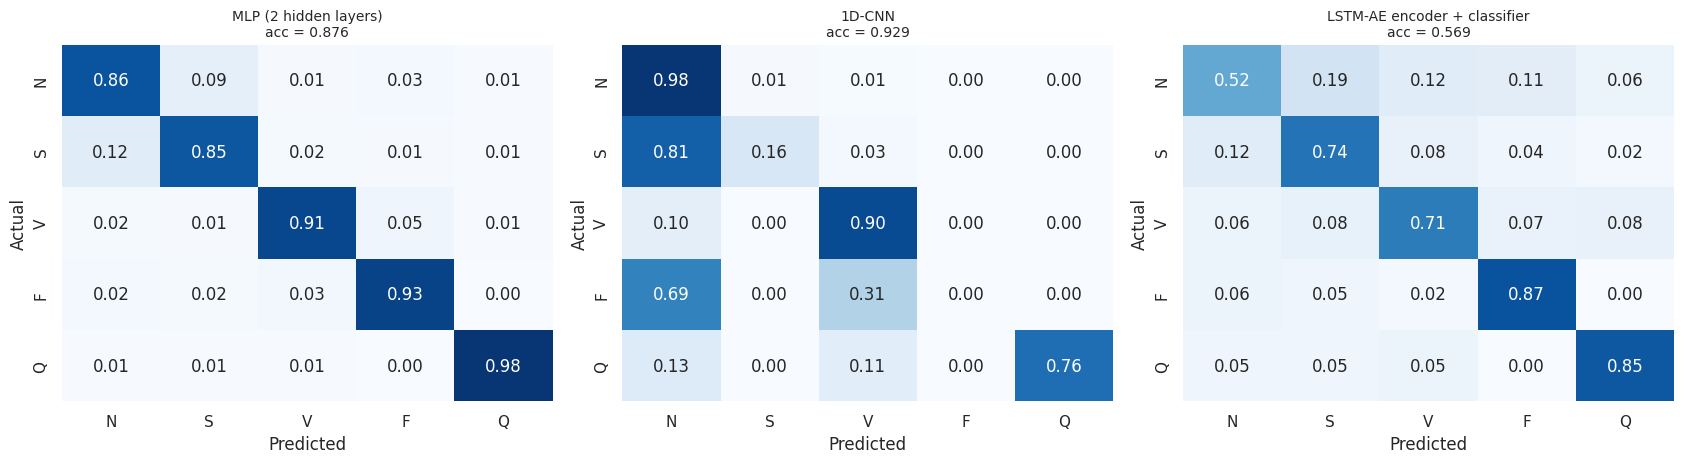

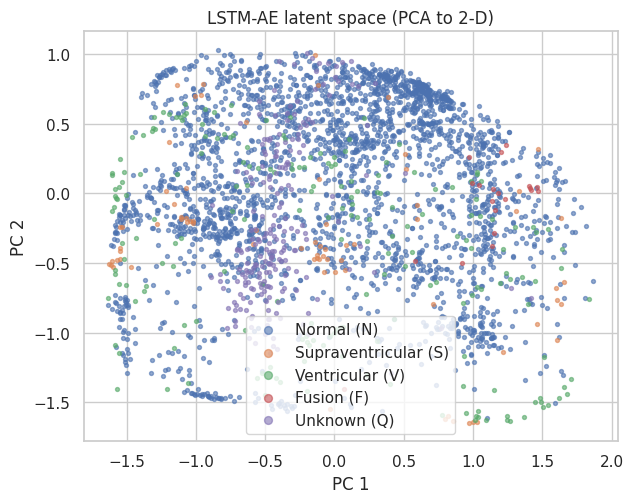

In [14]:
# Confusion matrices (5-class) + latent space
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for a, r in zip(ax, (r_mlp, r_cnn, r_head)):
    cm = confusion_matrix(yte, r["yp"], labels=range(5)).astype(float)
    cmn = np.divide(cm, cm.sum(1, keepdims=True), out=np.zeros_like(cm), where=cm.sum(1, keepdims=True) > 0)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=a,
                xticklabels=CLASSES, yticklabels=CLASSES)
    a.set_title(f"{r['name']}\nacc = {r['acc']:.3f}", fontsize=10); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
save_fig(fig, "fig10_confusion_matrices_5class.png")

n = min(3000, len(Zte)); idx = np.random.RandomState(SEED).choice(len(Zte), n, replace=False)
P = PCA(2, random_state=SEED).fit_transform(Zte[idx])
fig, ax = plt.subplots(figsize=(6.5, 5.2))
for c in range(5):
    m = yte[idx] == c
    if m.any():
        ax.scatter(P[m, 0], P[m, 1], s=8, alpha=0.6, label=CLASS_FULL[c])
ax.set_title("LSTM-AE latent space (PCA to 2-D)"); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(markerscale=2)
save_fig(fig, "fig11_latent_space_pca.png")


=== 5-class classification ===
                        Model                   Task  Accuracy  Macro_F1  Weighted_F1  Params  Train_time_s
       MLP (2 hidden layers) 5-class classification    0.8762    0.6894       0.9043   32645          36.3
                      1D-CNN 5-class classification    0.9293    0.5714       0.9215   44677          43.6
LSTM-AE encoder + classifier 5-class classification    0.5687    0.4120       0.6464   32517          83.5

=== Anomaly detection (normal vs abnormal) ===
            Model  ROC_AUC  Precision  Recall     F1  Accuracy  Threshold  Params  Train_time_s
LSTM-Autoencoder   0.8536     0.5827  0.6489 0.6140    0.8594     0.0104   63492          52.3
 GRU-Autoencoder   0.8386     0.5659  0.6290 0.5958    0.8529     0.0113   48260          49.0
 RNN-Autoencoder   0.7694     0.4343  0.5599 0.4892    0.7984     0.0123   16068          66.1

=== Optimiser study ===
            Optimizer  Final_train_loss  Final_val_loss  Final_val_acc  Test_acc  Tes

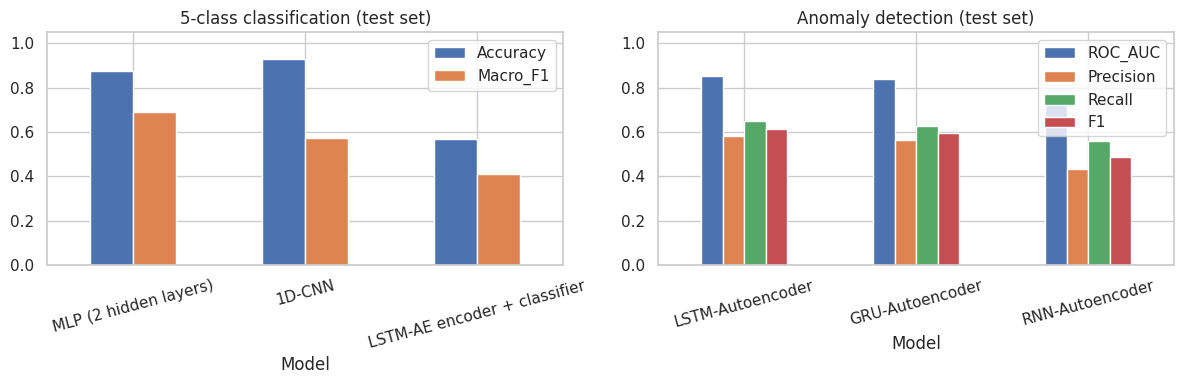


Saved everything to /content/outputs


In [15]:
# Final comparison tables and figure
res_df = pd.DataFrame(results); res_df.to_csv(RES / "classification_results.csv", index=False)
print("\n=== 5-class classification ===\n", res_df.round(4).to_string(index=False))
print("\n=== Anomaly detection (normal vs abnormal) ===\n", anom_df.round(4).to_string(index=False))
print("\n=== Optimiser study ===\n", opt_df.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rd = res_df.set_index("Model")[["Accuracy", "Macro_F1"]]
rd.plot.bar(ax=ax[0], rot=15); ax[0].set_ylim(0, 1.05); ax[0].set_title("5-class classification (test set)")
ad = anom_df.set_index("Model")[["ROC_AUC", "Precision", "Recall", "F1"]]
ad.plot.bar(ax=ax[1], rot=15); ax[1].set_ylim(0, 1.05); ax[1].set_title("Anomaly detection (test set)")
save_fig(fig, "fig12_model_comparison.png")

(RES / "model_summaries.txt").write_text("\n\n".join(f"##### {k} #####\n{v}" for k, v in summaries.items()))
(RES / "classification_reports.txt").write_text("\n\n".join(f"##### {k} #####\n{v}" for k, v in reports.items()))
json.dump(dict(config={k: str(v) for k, v in CFG.items()}, demo=DEMO,
               classification=results, anomaly=anom_rows, optimizers=opt_rows),
          open(RES / "all_results.json", "w"), indent=2, default=float)
print("\nSaved everything to", OUT.resolve())